# Current distribution: primary, secondary and porous electrodes

This tutorial is written for readers who know COMSOL's *Primary and Secondary Current Distribution* and *Porous
Electrode* features. It solves the same problems with `axionfem.chem` (beta):

1. a primary current distribution on a disk electrode, compared with Newman's closed form;
2. secondary distributions with Butler–Volmer kinetics: the Wagner number, potentiostatic and galvanostatic control,
   and Newton strategies for large overpotentials;
3. a 3D concentric-electrode cell on several MPI ranks;
4. a porous electrode with linearized kinetics, compared with its closed form;
5. pointers to the tests and validation notes.

The electrolyte carries no concentration gradients: the electrolyte potential $\phi_l$ obeys

$$
\nabla\cdot\mathbf i_l = 0,\qquad \mathbf i_l=-\kappa\nabla\phi_l ,
$$

with conductivity $\kappa$, insulating walls $\mathbf i_l\cdot\mathbf n=0$ by default, and one condition per electrode.

| COMSOL | `axionfem.chem` |
|---|---|
| Electrolyte, conductivity $\sigma_l$ | `set_conductivity({attr: kappa})` (or a function of position) |
| Electrode Surface, primary condition | `add_electrode(name, attrs, primary=True, phi_s=..., E_eq=...)`: $\phi_l=\phi_s-E_{eq}$ |
| Electrode Reaction: Butler–Volmer, linearized BV, anodic or cathodic Tafel | `Reaction("bv" \| "linear" \| "tafel_a" \| "tafel_c", i0=..., E_eq=..., alpha_a=..., alpha_c=..., A=...)` |
| Several reactions on one surface | `reactions=[Reaction(...), Reaction(...)]` |
| Electric potential (external) | `phi_s=...` (potentiostatic) |
| Total current | `galvanostatic=True, current=...` (`phi_s` is then the initial guess) |
| Insulation | the default on every boundary without an electrode |
| Infinite element domain (axisymmetric half space above an insulating plane) | `set_exterior_halfspace(attr, Rb, modes, kappa)` |
| 2D axisymmetric component | `CurrentDistribution(mesh, axisymmetric=True)`, mesh in the meridian $(r, z)$ |
| 3D component | `CurrentDistribution3D` (MPI) |
| Porous Electrode, linearized BV | `PorousElectrode` (1D) |

The conventions are COMSOL's: SI units, anodic current positive, overpotential $\eta=\phi_s-\phi_l-E_{eq}$. In
axisymmetry a galvanostatic `current` is the 3D total, $2\pi\int i\,r\,ds$. The raw arrays the solver returns are per
radian (`residual_full` and `boundary_mass` carry $r$) or carry no $r$ (the `boundary_quadrature` weights), so the
helpers below multiply by $2\pi$ or $2\pi r$.

Run this notebook from `examples/` in a source checkout (section 2 reads a reference file under
`benchmarks/chem/`), with NumPy, SciPy and Matplotlib; section 3 needs the MPI build of the compiled core and starts 4 ranks when an MPI launcher is available (`srun` in a SLURM job, `mpirun` or `mpiexec`).

In [1]:
import json, math, os, shlex, shutil, subprocess, sys, tempfile, textwrap
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from scipy.optimize import brentq
import scipy.sparse.linalg as spla

import warnings
# show warnings without the temporary file name the kernel gives each cell
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"

import axionfem as af
from axionfem.chem import (CurrentDistribution, PorousElectrode, Reaction, ConvergenceError, meshes,
                           FARADAY as F, GAS_CONSTANT as R)

REPO = Path.cwd().parent                            # the source checkout (benchmark data), when run from examples/
T = 298.15                                          # K
f = F / (R * T)                                     # 1/V
print("axionFEM", af.__version__, f"| F/RT = {f:.3f} 1/V")

plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.8, "legend.frameon": False})
BLUE, ORANGE, GREEN, GOLD, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#6f6e69"


def kinetic_current(cd, attrs, phi_s, reactions, axisymmetric):
    # electrode current from the electrode's boundary quadrature: integral of the reaction current densities
    q = cd.boundary_quadrature(list(attrs), cd.boundary_degree)
    phi = np.asarray(q["phi"])
    i = np.zeros_like(phi)
    for rx in reactions:
        eta = phi_s - phi - rx.E_eq
        if rx.kind == "bv":
            i += rx.i0 * (np.exp(rx.alpha_a * f * eta) - np.exp(-rx.alpha_c * f * eta))
        elif rx.kind == "linear":
            i += rx.i0 * (rx.alpha_a + rx.alpha_c) * f * eta
        else:
            raise ValueError(rx.kind)
    w = np.asarray(q["w"]) * (2 * math.pi * np.asarray(q["x"])[:, 0] if axisymmetric else 1.0)
    return float(np.sum(i * w))


def reaction_current(cd, k, axisymmetric):
    # current of electrode k from the weak-form residual (works for primary electrodes too)
    res = np.asarray(cd.residual_full(k))
    return float(res[np.asarray(cd.electrode_dofs(k), int)].sum()) * (2 * math.pi if axisymmetric else 1.0)


def density_on_electrode(cd, k, r):
    # current density on electrode k at radii r: boundary-mass projection of the residual
    dofs = np.asarray(cd.electrode_dofs(k), int)
    Mb = cd.boundary_mass(cd.electrode_attrs(k)).tocsr()[dofs][:, dofs].tocsc()
    lam = spla.spsolve(Mb, np.asarray(cd.residual_full(k))[dofs])
    rd = np.asarray(cd.dof_coordinates())[dofs, 0]
    o = np.argsort(rd)
    return np.interp(r, rd[o], lam[o])

axionFEM 0.1.0 | F/RT = 38.922 1/V


## 1. Primary current distribution on a disk

A disk electrode of radius $r_0$ lies in an insulating plane under a semi-infinite electrolyte; the counter electrode
is at infinity. In the primary distribution the electrolyte next to the disk is at $\phi_l=V$ (no kinetic resistance)
and $\phi_l\to0$ far away. Newman's solution gives the total current and the current density on the disk:

$$
I=4\kappa r_0 V,\qquad i(r)=\frac{2\kappa V}{\pi\sqrt{r_0^2-r^2}} .
$$

The density diverges as $(r_0-r)^{-1/2}$ at the edge of the disk, where the electrode meets the insulator.

The model is axisymmetric and lives in the quarter disk $\rho<R_b=5r_0$ of the meridian. The exterior
$\rho>R_b$ is replaced by a Dirichlet-to-Neumann map on the outer arc (`set_exterior_halfspace`, 12 even Legendre
modes; the neglected modes are of order $(r_0/R_b)^{24}$), the counterpart of an infinite element domain.
`meshes.disk_graded(n, beta=...)` builds a polar mesh: $2n$ intervals across the disk radius, and grading
$\beta>1$ concentrates elements at the disk edge. The boundary attributes are 1 disk, 2 insulating plane, 3 axis,
4 outer arc.

In [2]:
r0, V = 1e-3, 0.1             # m, V
kap = 1.0                     # S/m
I_newman = 4 * kap * r0 * V


def disk_model(n, beta=3.0, order=2, kappa=kap):
    cd = CurrentDistribution(meshes.disk_graded(n, r0=r0, Rb=5 * r0, beta=beta), order=order, axisymmetric=True)
    cd.set_conductivity({1: kappa})
    return cd


def solve_primary_disk(n, beta=3.0, order=2):
    cd = disk_model(n, beta, order)
    cd.add_electrode("disk", [1], primary=True, phi_s=V)
    cd.set_exterior_halfspace(4, 5 * r0, 12, kap)
    cd.solve(temperature=T)
    return cd


cd = solve_primary_disk(8)
I = reaction_current(cd, 0, True)
print(f"P2, graded n = 8: {cd.mesh_stats()['n_elements']} triangles, {cd.num_dofs()} dofs")
print(f"I = {I * 1e3:.5f} mA   Newman 4 kappa r0 V = {I_newman * 1e3:.5f} mA   relative error {I / I_newman - 1:.1e}")

P2, graded n = 8: 3040 triangles, 6209 dofs
I = 0.40041 mA   Newman 4 kappa r0 V = 0.40000 mA   relative error 1.0e-03


The current is the sum of the weak-form residual over the disk's degrees of freedom (the *reaction current*). It
converges faster than the flux of the gradient, which is singular at the edge.

The figure shows the electrolyte potential near the disk and the current density along it against Newman's
formula.

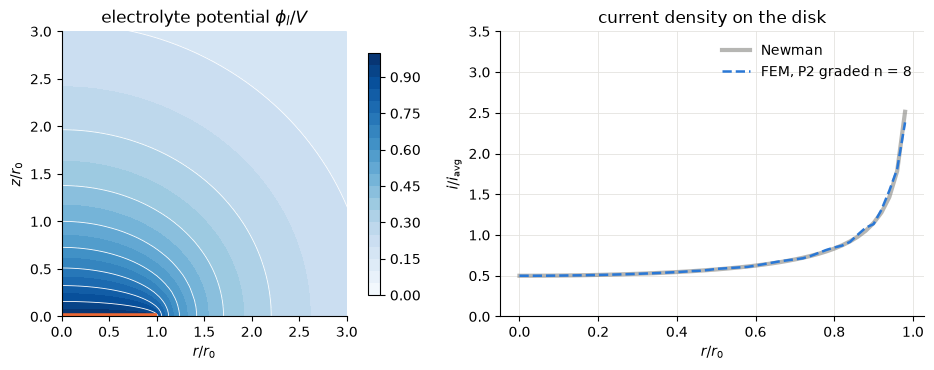

In [3]:
X = np.asarray(cd.dof_coordinates())
phi = np.asarray(cd.phi_dofs())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
tri = mtri.Triangulation(X[:, 0] / r0, X[:, 1] / r0)
m = ax[0].tricontourf(tri, phi / V, levels=np.linspace(0, 1, 21), cmap="Blues")
ax[0].tricontour(tri, phi / V, levels=np.linspace(0.1, 0.9, 9), colors="white", linewidths=0.6)
ax[0].plot([0, 1], [0, 0], color=ORANGE, lw=4, solid_capstyle="butt")
ax[0].set(xlim=(0, 3), ylim=(0, 3), aspect="equal", xlabel="$r/r_0$", ylabel="$z/r_0$",
          title=r"electrolyte potential $\phi_l/V$")
ax[0].grid(False)
fig.colorbar(m, ax=ax[0], shrink=0.85)

rs = np.linspace(0, 0.98, 50) * r0
i_avg = I_newman / (math.pi * r0 ** 2)
ax[1].plot(rs / r0, 2 * kap * V / (math.pi * np.sqrt(r0 ** 2 - rs ** 2)) / i_avg, color=GREY, lw=3, alpha=0.5,
           label="Newman")
ax[1].plot(rs / r0, density_on_electrode(cd, 0, rs) / i_avg, color=BLUE, ls="--", label="FEM, P2 graded n = 8")
ax[1].set(xlabel="$r/r_0$", ylabel=r"$i/i_{\rm avg}$", title="current density on the disk", ylim=(0, 3.5))
ax[1].legend()
plt.tight_layout()
plt.show()

### Mesh convergence and the edge singularity

On a uniform mesh ($\beta=1$) the singular edge limits the error in $I$ to first order in $h$, whatever the element
order. Grading with $\beta=3$ raises the order of the current error to $\min(2p,\beta)$ for elements of order $p$: 2
for P1, its smooth-problem rate, and 3 for P2, which would need $\beta>4$ to reach its smooth rate 4. On these coarse
meshes the fitted orders approach 2 and 3, which finer levels of the same family reach. This is why meshes are refined at electrode–insulator junctions.

P1 beta=1: I/I_Newman - 1 = 1.42e-01  6.77e-02  3.28e-02  1.61e-02
P2 beta=1: I/I_Newman - 1 = 4.19e-02  1.98e-02  9.60e-03  4.73e-03
P1 beta=3: I/I_Newman - 1 = 1.49e-01  5.14e-02  1.65e-02  4.66e-03
P2 beta=3: I/I_Newman - 1 = 4.13e-02  6.84e-03  1.03e-03  1.37e-04


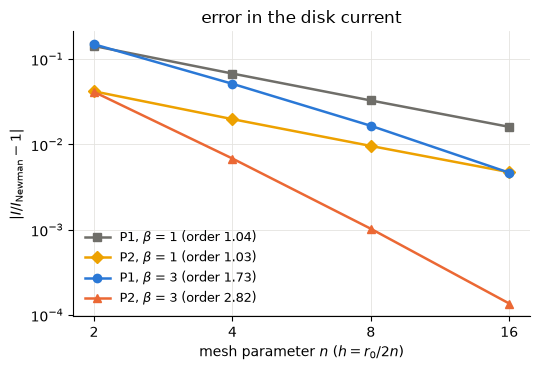

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for beta, order, col, mk in ((1.0, 1, GREY, "s"), (1.0, 2, GOLD, "D"), (3.0, 1, BLUE, "o"), (3.0, 2, ORANGE, "^")):
    ns, err = [2, 4, 8, 16], []
    for n in ns:
        err.append(reaction_current(solve_primary_disk(n, beta, order), 0, True) / I_newman - 1)
    p = np.polyfit(np.log(1 / np.array(ns[-3:])), np.log(np.abs(err[-3:])), 1)[0]
    ax.loglog(ns, np.abs(err), marker=mk, color=col, label=rf"P{order}, $\beta$ = {beta:g} (order {p:.2f})")
    print(f"P{order} beta={beta:g}: I/I_Newman - 1 =", "  ".join(f"{e:.2e}" for e in err))
ax.set(xlabel="mesh parameter $n$ ($h = r_0/2n$)", ylabel=r"$|I/I_{\rm Newman}-1|$",
       title="error in the disk current")
ax.set_xticks(ns, [str(n) for n in ns])
ax.minorticks_off()
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 2. Secondary current distribution

### Linear kinetics and the Wagner number

With electrode kinetics the electrolyte next to the electrode is no longer at a fixed potential. The kinetic
resistance competes with the ohmic resistance of the electrolyte; their ratio is the Wagner number,

$$
\mathrm{Wa}=\frac{\kappa}{L}\,\frac{\partial\eta}{\partial i},
$$

with $L$ a length of the cell. For linearized Butler–Volmer kinetics, $i=i_0(\alpha_a+\alpha_c)\,f\,\eta$ with
$f=F/RT$, so $\partial\eta/\partial i$ is a constant. For the disk Newman uses the inverse,

$$
J=\frac{(\alpha_a+\alpha_c)\,F\,i_0\,r_0}{RT\,\kappa}=\frac1{\mathrm{Wa}}\quad(L=r_0).
$$

Large $J$ (fast kinetics) recovers the primary distribution, $I\to4\kappa r_0V$. Small $J$ gives a uniform
distribution limited by the kinetics, $I\to\pi r_0^2\,i_0(\alpha_a+\alpha_c)fV$, i.e.
$I/(4\kappa r_0V)\to\pi J/4$.

The cell below sweeps $J$ over four decades at a fixed applied potential. The reference values for
$I/(4\kappa r_0 V)$ come from an independent Legendre-series solution stored with the benchmark data. The conductivity is
$2.5\ \mathrm{S/m}$ here; the ratio is independent of $\kappa$ at fixed $J$.

In [5]:
kap2 = 2.5
series = json.loads((REPO / "benchmarks/chem/refdata/c3/disk_series.json").read_text())["Js"]


def disk_kinetic(n, reactions, phi_s=V, galvanostatic=False, current=0.0):
    cd = disk_model(n, kappa=kap2)
    cd.add_electrode("disk", [1], reactions=reactions, phi_s=phi_s, galvanostatic=galvanostatic, current=current)
    cd.set_exterior_halfspace(4, 5 * r0, 12, kap2)
    cd.set_temperature(T)
    return cd


Js = [0.01, 0.1, 1.0, 10.0, 100.0]
ratio, profiles = [], {}
rs = np.linspace(0, 0.95, 40) * r0
print("     J    I/(4 kappa r0 V)   series         rel. diff")
for J in Js:
    i0 = J * kap2 * R * T / (F * r0)            # alpha_a + alpha_c = 1
    rx = Reaction("linear", i0=i0)
    cd = disk_kinetic(8, [rx])
    cd.solve()
    I = kinetic_current(cd, [1], V, [rx], True)
    ratio.append(I / (4 * kap2 * r0 * V))
    ref = series[str(J)]["value"]
    print(f"{J:7.2f}   {ratio[-1]:.8f}       {ref:.8f}     {ratio[-1] / ref - 1:+.1e}")
    profiles[J] = density_on_electrode(cd, 0, rs) / (I / (math.pi * r0 ** 2))

     J    I/(4 kappa r0 V)   series         rel. diff
   0.01   0.00778789       0.00778788     +4.9e-07
   0.10   0.07240146       0.07240113     +4.6e-06
   1.00   0.42669340       0.42667971     +3.2e-05
  10.00   0.85877616       0.85867216     +1.2e-04
 100.00   0.97846457       0.97817953     +2.9e-04


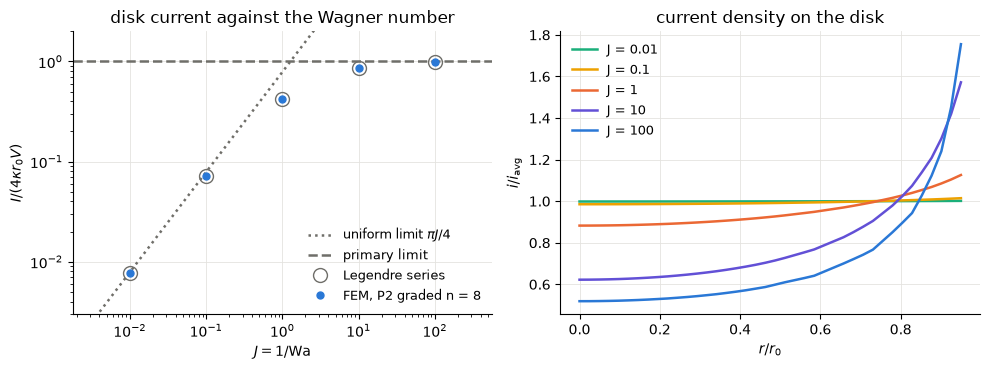

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
Jg = np.logspace(-2.5, 2.5, 100)
ax[0].loglog(Jg, np.pi * Jg / 4, color=GREY, ls=":", label=r"uniform limit $\pi J/4$")
ax[0].axhline(1, color=GREY, ls="--", label="primary limit")
ax[0].loglog(Js, [series[str(J)]["value"] for J in Js], "o", ms=10, mfc="none", color=GREY, label="Legendre series")
ax[0].loglog(Js, ratio, "o", color=BLUE, ms=5, label="FEM, P2 graded n = 8")
ax[0].set(xlabel=r"$J = 1/\mathrm{Wa}$", ylabel=r"$I/(4\kappa r_0 V)$", ylim=(3e-3, 2),
          title="disk current against the Wagner number")
ax[0].legend(fontsize=9)
for J, col in zip(Js, (GREEN, GOLD, ORANGE, VIOLET, BLUE)):
    ax[1].plot(rs / r0, profiles[J], color=col, label=f"J = {J:g}")
ax[1].set(xlabel="$r/r_0$", ylabel=r"$i/i_{\rm avg}$", title="current density on the disk")
ax[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

The distribution is almost uniform at $J=0.01$ and approaches the primary shape, with its peak at the edge, at
$J=100$. On this mesh the large-$J$ cases have the largest error, because their edge peak is sharpest.

### Butler–Volmer kinetics

With full Butler–Volmer kinetics,

$$
i=i_0\left[e^{\alpha_a f\eta}-e^{-\alpha_c f\eta}\right],
$$

$\partial\eta/\partial i$ falls as the current grows, so the effective Wagner number falls and the distribution moves
toward the primary one as the applied potential rises. Below, $i_0$ is set so that $J=1$ at small overpotential.

**Potentiostatic control** fixes the metal potential $\phi_s$ and returns the current. **Galvanostatic control** fixes
the total current and solves for $\phi_s$, which adds one unknown and one equation (the counterpart of COMSOL's
*Total current* condition). A galvanostatic electrode needs a potential reference: another potentiostatic
electrode, or as here the half-space exterior, which holds $\phi_l\to0$ at infinity. The solver refuses a problem whose
electrodes are all galvanostatic and that has no exterior condition.

In [7]:
i0_J1 = 1.0 * kap2 * R * T / (F * r0)
bv = Reaction("bv", i0=i0_J1, E_eq=0.0, alpha_a=0.5, alpha_c=0.5)

pot = disk_kinetic(8, [bv], phi_s=1.0)
rep = pot.solve()
I_pot = kinetic_current(pot, [1], 1.0, [bv], True)
print(f"potentiostatic: phi_s = 1.000 V      -> I = {I_pot * 1e3:.6f} mA   ({rep['iterations']} Newton iterations)")

gal = disk_kinetic(8, [bv], phi_s=0.0, galvanostatic=True, current=I_pot)     # phi_s = 0 is only the start
rep = gal.solve()
print(f"galvanostatic:  I = {I_pot * 1e3:.6f} mA -> phi_s = {gal.phi_s()[0]:.12f} V   ({rep['iterations']} Newton "
      f"iterations, constraint residual {rep['constraint_residual']:.1e})")

potentiostatic: phi_s = 1.000 V      -> I = 7.986569 mA   (22 Newton iterations)
galvanostatic:  I = 7.986569 mA -> phi_s = 1.000000000000 V   (7 Newton iterations, constraint residual 1.2e-15)


The two controls give the same state. The report of every solve carries `iterations`, `relative_residual`,
`residual_history`, `stop` and `constraint_residual` (the relative mismatch of a galvanostatic current).
Newton iterates until the relative residual stops halving below `stag` ($10^{-13}$), so the count includes one or two
steps at round-off after convergence. `ConvergenceError` is raised when the final residual is above the gate
($10^{-12}$) or the exponent clip is still active; pass `check=False` to receive the report instead.

### Large overpotentials: the initial guess, warm starts and continuation

Newton starts by default from $\phi_l=0$, so the whole applied potential first sits on the interface. Far above the
solution, each Newton step on the exponential branch lowers $\alpha_a f\eta$ by about one, i.e. $\eta$ by
$RT/(\alpha_a F)\approx51\ \mathrm{mV}$ here, so a few volts need more than the 60 iterations allowed (79 at 4 V). The
step limiter ($|\Delta\eta|\le10\,RT/F$ per step) is not the cause, as `0 limited steps` shows; it caps the large
steps Newton takes when it approaches the solution from below.

In [8]:
big = disk_kinetic(8, [bv], phi_s=4.0)
try:
    big.solve()
except ConvergenceError as e:
    print(textwrap.fill(str(e), 110))

Newton did not converge: stop 'max_iter' after 60 iterations, relres 9.904e-01 (gate 1e-12), 0 limited steps,
exponent clip active: False, initial guess 'zero'.  For large cell voltages start from initial='primary', or
continue in the applied potential (set_control + initial='state', see solve_continuation); raise max_iter only
if the history still falls.


There are two remedies.

* `initial="primary"` starts from the primary distribution ($\eta=0$ on every electrode: one linear solve). Most of a
  large voltage is ohmic drop, so this start is close to the answer.
* Continuation: change the control with `set_control(electrode, value)` and solve again with `initial="state"`, so each
  solve starts from the previous solution. `solve_continuation(electrode, values)` runs that loop and returns the last
  report; for a polarization curve, run the loop yourself and keep each current. It is the counterpart of
  COMSOL's auxiliary sweep in a Stationary study step with continuation.

In [9]:
big = disk_kinetic(8, [bv], phi_s=4.0)
rep = big.solve(initial="primary")
print(f"initial='primary' at 4 V: converged in {rep['iterations']} iterations, "
      f"I = {kinetic_current(big, [1], 4.0, [bv], True) * 1e3:.4f} mA")

cont = disk_kinetic(8, [bv], phi_s=0.25)
rep = cont.solve_continuation(0, np.arange(0.25, 4.01, 0.25))
print(f"solve_continuation 0.25 -> 4 V: last step {rep['iterations']} iterations, "
      f"I = {kinetic_current(cont, [1], 4.0, [bv], True) * 1e3:.4f} mA")

# a polarization curve by continuation, with the current density profile at three potentials
Vs, Is, prof = np.arange(0.05, 4.01, 0.05), [], {}
cd = disk_kinetic(8, [bv], phi_s=Vs[0])
for j, v in enumerate(Vs):
    cd.set_control(0, float(v))
    cd.solve(initial="zero" if j == 0 else "state")
    Is.append(kinetic_current(cd, [1], float(v), [bv], True))
    if round(v, 2) in (0.1, 0.5, 4.0):
        prof[round(v, 2)] = density_on_electrode(cd, 0, rs) / (Is[-1] / (math.pi * r0 ** 2))
Is = np.array(Is)

initial='primary' at 4 V: converged in 9 iterations, I = 37.1891 mA
solve_continuation 0.25 -> 4 V: last step 11 iterations, I = 37.1891 mA


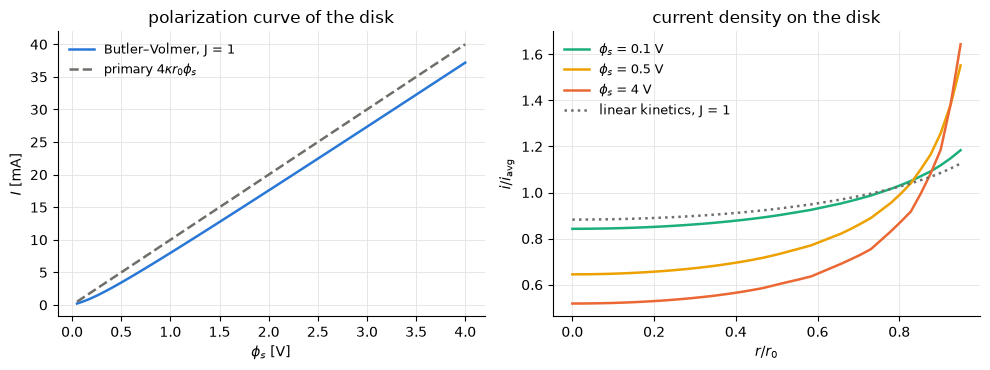

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(Vs, Is * 1e3, color=BLUE, label="Butler–Volmer, J = 1")
ax[0].plot(Vs, 4 * kap2 * r0 * Vs * 1e3, color=GREY, ls="--", label=r"primary $4\kappa r_0\phi_s$")
ax[0].set(xlabel=r"$\phi_s$ [V]", ylabel="$I$ [mA]", title="polarization curve of the disk")
ax[0].legend(fontsize=9)
for v, col in zip((0.1, 0.5, 4.0), (GREEN, GOLD, ORANGE)):
    ax[1].plot(rs / r0, prof[v], color=col, label=rf"$\phi_s$ = {v:g} V")
ax[1].plot(rs / r0, profiles[1.0], color=GREY, ls=":", label="linear kinetics, J = 1")
ax[1].set(xlabel="$r/r_0$", ylabel=r"$i/i_{\rm avg}$", title="current density on the disk")
ax[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

At $\phi_s=0.1\ \mathrm V$ the Butler–Volmer distribution is close to the linear one at the same $J$, and already slightly
less uniform, because $\eta$ there is comparable to $RT/F$. At 4 V it has moved most of the
way toward the primary shape (compare $J=100$ above), and the polarization curve runs parallel to the primary line, offset by the kinetic
overpotential, which grows only logarithmically with the current.

## 3. Three dimensions: concentric electrodes on MPI ranks

`CurrentDistribution3D` solves the same equations on tetrahedral meshes (P1, or isoparametric P2), partitioned over MPI
ranks (METIS), with conjugate gradients and an algebraic multigrid preconditioner. Every rank builds the same mesh. Arrays
returned by the solver (quadrature points, residual rows) are the rank's own part, so currents are summed over ranks.

The cells are sectors of concentric electrodes: a quarter of a cylindrical annulus ($r_1<\rho<r_2$, height
$H$) and a sector of a spherical shell (polar angle $\pi/4$ to $\pi/2$, azimuth $0$ to $\pi/2$), with insulating cut faces.
`meshes3d.sector(N, "cyl3d" | "sph3d", order)` builds them with fixed dimensions ($r_1$ = `meshes3d.R1` = 5 mm,
$r_2$ = `meshes3d.R2` = 20 mm, $H$ = `meshes3d.H_CYL` = 10 mm); attribute 1 is the inner electrode and 2 the outer one.
The field is radial, so the cell is a series circuit of the two interfaces and the electrolyte resistance

$$
R_{\rm el}^{\rm cyl}=\frac{\ln(r_2/r_1)}{\kappa\,\Theta H},\qquad
R_{\rm el}^{\rm sph}=\frac{1/r_1-1/r_2}{\kappa\,\Omega},
$$

with $\Theta=\pi/2$ the sector angle and $\Omega=\frac{\pi}{2}\cos\frac{\pi}{4}$ the sector's solid angle. The primary
current is $I=\Delta\phi/R_{\rm el}$. With symmetric Butler–Volmer kinetics
($\alpha_a=\alpha_c=\tfrac12$), $\eta=\frac2f\,\mathrm{arcsinh}\,\frac{i}{2i_0}$, and the cell voltage

$$
\phi_{s,1}-\phi_{s,2}=\eta_1\!\left(\frac{I}{A_1}\right)-\eta_2\!\left(-\frac{I}{A_2}\right)+E_{eq,1}-E_{eq,2}+IR_{\rm el}
$$

is one equation for $I$, with $A_1$, $A_2$ the electrode areas.

These cells need the MPI build of axionFEM and are skipped otherwise. The next cell writes a short script and runs it on 4 MPI ranks, started by the launcher that `Design.solve` uses:
`$AXF_MPI_LAUNCHER` if it is set (it may carry options, for example `srun --overlap` inside an interactive `srun`
step), else `srun` inside a SLURM job, else `mpirun` or `mpiexec`. Without a launcher, or when the launch fails, the
same function runs in this kernel on 1 rank.

In [11]:
WORKER = r"""
import json, sys
import numpy as np

PRIMARY_PHI = (0.2, 0.0)                                   # V on the inner and outer electrode
BV_INNER = dict(phi_s=0.6, i0=10.0, E_eq=0.05)             # symmetric BV, alpha_a = alpha_c = 1/2
BV_OUTER = dict(phi_s=0.0, i0=10.0, E_eq=-0.02)


def run(geom, kin, order, N, T=298.15):
    from axionfem.chem import CurrentDistribution3D, Reaction, meshes3d, FARADAY, GAS_CONSTANT
    f = FARADAY / (GAS_CONSTANT * T)
    cd = CurrentDistribution3D(meshes3d.sector(N, geom, order), order=order)
    cd.set_conductivity(1.0)
    if kin == "primary":
        cd.add_electrode("inner", [1], primary=True, phi_s=PRIMARY_PHI[0])
        cd.add_electrode("outer", [2], primary=True, phi_s=PRIMARY_PHI[1])
    else:
        rx = Reaction("bv", i0=BV_INNER["i0"], E_eq=BV_INNER["E_eq"])
        cd.add_electrode("inner", [1], reactions=[rx], phi_s=BV_INNER["phi_s"])
        cd.add_electrode("outer", [2], reactions=[Reaction("bv", i0=BV_OUTER["i0"], E_eq=BV_OUTER["E_eq"])],
                         phi_s=BV_OUTER["phi_s"])
    rep = cd.solve(temperature=T)
    if kin == "primary":                      # reaction current: residual rows owned by this rank
        res = np.asarray(cd.residual_full(-1))
        I = float(res[np.asarray(cd.attr_true_dofs([1]), int)].sum())
    else:                                     # kinetic current: this rank's boundary quadrature points
        q = cd.boundary_quadrature([1], cd.boundary_degree)
        eta = BV_INNER["phi_s"] - np.asarray(q["phi"]) - rx.E_eq
        i = rx.i0 * (np.exp(rx.alpha_a * f * eta) - np.exp(-rx.alpha_c * f * eta))
        I = float(np.sum(i * np.asarray(q["w"])))
    return dict(rank=cd.rank(), ranks=cd.ranks(), I=I, dofs=int(cd.global_true_dofs()),
                elements=int(cd.global_elements()), iterations=int(rep["iterations"]),
                converged=bool(rep["converged"]), cg_max=int(cd.diagnostics()["cg_iterations_max"]))


if __name__ == "__main__":
    sys.path.insert(0, sys.argv[1])           # the axionfem package of the notebook
    print(json.dumps(run(sys.argv[2], sys.argv[3], int(sys.argv[4]), int(sys.argv[5]))))
"""
import atexit
work = Path(tempfile.mkdtemp(prefix="axf_chem3d_"))
atexit.register(shutil.rmtree, work, True)      # removed when the kernel exits
(work / "chem3d_worker.py").write_text(WORKER)
PKG = str(Path(af.__file__).resolve().parents[1])
def mpi_launcher():
    # the launcher Design.solve uses: $AXF_MPI_LAUNCHER, else srun inside a SLURM job, else mpirun, else mpiexec
    if os.environ.get("AXF_MPI_LAUNCHER"):
        return shlex.split(os.environ["AXF_MPI_LAUNCHER"])
    if os.environ.get("SLURM_JOB_ID") and shutil.which("srun"):
        return ["srun"]
    for name in ("mpirun", "mpiexec"):
        if shutil.which(name):
            return [name]
    return None


def is_open_mpi(launcher):
    # Open MPI's mpirun needs --oversubscribe on machines with fewer than 4 cores; other launchers reject the option
    try:
        v = subprocess.run([launcher[0], "--version"], capture_output=True, text=True, timeout=60)
    except (OSError, subprocess.TimeoutExpired):
        return False
    return "Open MPI" in v.stdout + v.stderr


LAUNCHER = mpi_launcher()
SRUN = bool(LAUNCHER) and os.path.basename(LAUNCHER[0]) == "srun"
OPEN_MPI = bool(LAUNCHER) and not SRUN and is_open_mpi(LAUNCHER)
IN_KERNEL = {}
exec(compile(WORKER, "chem3d_worker", "exec"), IN_KERNEL)     # the same run() for the 1-rank path


def solve3d(geom, kin, order, N, ranks):
    # total current of the inner electrode, summed over the ranks
    if ranks > 1:
        # drop the variables of an enclosing MPI launch (a kernel started under srun or mpirun), or the child
        # processes would try to join it
        env = {k: v for k, v in os.environ.items() if not k.startswith(("OMPI_COMM", "PMIX_", "OMPI_MCA_ess"))}
        env["OMP_NUM_THREADS"] = "1"
        if SRUN:                                  # as Design.solve: pass this environment to the ranks, and drop
            env["SLURM_EXPORT_ENV"] = "ALL"       # memory settings that srun refuses in combination
            if "SLURM_MEM_PER_NODE" in env:
                env.pop("SLURM_MEM_PER_CPU", None)
                env.pop("SLURM_MEM_PER_GPU", None)
            env.pop("SLURM_TRES_PER_TASK", None)
        cmd = LAUNCHER + ["-n", str(ranks)] + (["--oversubscribe", "--bind-to", "none"] if OPEN_MPI else []) + [
            sys.executable, str(work / "chem3d_worker.py"), PKG, geom, kin, str(order), str(N)]
        out = subprocess.run(cmd, capture_output=True, text=True, env=env, cwd=work, check=True,
                             timeout=600).stdout
        parts = [json.loads(l) for l in out.splitlines() if l.startswith("{")]
    else:
        parts = [IN_KERNEL["run"](geom, kin, order, N)]
    if not (len(parts) == ranks and all(p["converged"] and p["ranks"] == ranks for p in parts)):
        raise RuntimeError(f"expected {ranks} converged ranks, got {[(p['ranks'], p['converged']) for p in parts]}")
    return dict(parts[0], I=sum(p["I"] for p in parts))


RANKS = 1
HAVE_3D = af.build_info()["mpi"]              # CurrentDistribution3D needs the MPI build
if not HAVE_3D:
    print("CurrentDistribution3D needs the MPI build of axionFEM (af.build_info()['mpi'] is False here): "
          "the 3D cells below are skipped.")
else:
    solve3d("sph3d", "primary", 1, 2, 1)      # the 1-rank path in this kernel
    if LAUNCHER:
        try:                                  # a failing launch falls back to 1 rank
            solve3d("sph3d", "primary", 1, 2, 4)
            RANKS = 4
        except (subprocess.CalledProcessError, subprocess.TimeoutExpired, RuntimeError, OSError) as e:
            print(f"the 4-rank launch did not work here ({type(e).__name__}); falling back to 1 rank")
    print(f"3D cases on {RANKS} MPI rank(s)")
    if RANKS == 1:
        print("The 3D cases run on 1 rank in this kernel; the results are the same up to round-off.")

3D cases on 4 MPI rank(s)


In [12]:
from axionfem.chem import meshes3d
r1, r2, H, kap3 = meshes3d.R1, meshes3d.R2, meshes3d.H_CYL, 1.0
Theta, Omega = math.pi / 2, math.pi / 2 * math.cos(math.pi / 4)
geo = {"cyl3d": dict(R_el=math.log(r2 / r1) / (kap3 * Theta * H), A1=Theta * r1 * H, A2=Theta * r2 * H),
       "sph3d": dict(R_el=(1 / r1 - 1 / r2) / (kap3 * Omega), A1=Omega * r1 ** 2, A2=Omega * r2 ** 2)}


def I_exact(geom, kin):
    g = geo[geom]
    if kin == "primary":
        return (IN_KERNEL["PRIMARY_PHI"][0] - IN_KERNEL["PRIMARY_PHI"][1]) / g["R_el"]
    bi, bo = IN_KERNEL["BV_INNER"], IN_KERNEL["BV_OUTER"]
    eta = lambda i, i0: 2 / f * math.asinh(i / (2 * i0))       # symmetric BV inverted
    cell = lambda I: (eta(I / g["A1"], bi["i0"]) - eta(-I / g["A2"], bo["i0"]) + bi["E_eq"] - bo["E_eq"]
                      + I * g["R_el"] - (bi["phi_s"] - bo["phi_s"]))
    return brentq(cell, 0.0, (bi["phi_s"] - bo["phi_s"]) / g["R_el"], xtol=1e-16, rtol=1e-15)


if HAVE_3D:
    print("geometry kinetics  order  N  elements   dofs  ranks  Newton  CG max   I [mA]       exact [mA]   rel. error")
    for geom in ("cyl3d", "sph3d"):
        for kin in ("primary", "bv"):
            for order, N in ((1, 8), (2, 4), (2, 8)):
                o = solve3d(geom, kin, order, N, RANKS)
                Ie = I_exact(geom, kin)
                print(f"{geom:8s} {kin:9s} P{order}  {N:3d} {o['elements']:8d} {o['dofs']:6d} {o['ranks']:5d} "
                      f"{o['iterations']:6d} {o['cg_max']:6d}   {o['I'] * 1e3:.8f}   {Ie * 1e3:.8f}  "
                      f"{o['I'] / Ie - 1:+.2e}")

geometry kinetics  order  N  elements   dofs  ranks  Newton  CG max   I [mA]       exact [mA]   rel. error
cyl3d    primary   P1    8     3072    729     4      3     16   2.28227426   2.26618007  +7.10e-03
cyl3d    primary   P2    4      384    729     4      3     22   2.26721279   2.26618007  +4.56e-04
cyl3d    primary   P2    8     3072   4913     4      3     28   2.26625580   2.26618007  +3.34e-05
cyl3d    bv        P1    8     3072    729     4     15     17   4.59631556   4.57046913  +5.66e-03
cyl3d    bv        P2    4      384    729     4     15     23   4.57204048   4.57046913  +3.44e-04
cyl3d    bv        P2    8     3072   4913     4     15     28   4.57058879   4.57046913  +2.62e-05
sph3d    primary   P1    8     3072    729     4      3     17   1.51272013   1.48096098  +2.14e-02
sph3d    primary   P2    4      384    729     4      3     23   1.48553765   1.48096098  +3.09e-03
sph3d    primary   P2    8     3072   4913     4      3     28   1.48134083   1.48096098  +2.

The P2 elements follow the curved electrodes (isoparametric mapping). At the same 729 unknowns, P2 on $N=4$ is 7 to 16
times more accurate than P1 on $N=8$, and from $N=4$ to 8 its error falls 12- to 14-fold. The cell below solves one
case on 1 rank in this kernel and, when the 4-rank launch works, compares it with the 4-rank run
(`tests/test_chem_current_distribution_3d.py::test_3d_rank_invariance` checks the same on 1 and 2 ranks):

In [13]:
if HAVE_3D:
    a = solve3d("sph3d", "bv", 2, 8, 1)
    print(f"1 rank in this kernel: I = {a['I']:.15e} A")
    if RANKS > 1:
        b = solve3d("sph3d", "bv", 2, 8, RANKS)
        print(f"{RANKS} ranks:              I = {b['I']:.15e} A   "
              f"relative difference {abs(b['I'] / a['I'] - 1):.1e}")

1 rank in this kernel: I = 2.906077946921848e-03 A
4 ranks:              I = 2.906077946921840e-03 A   relative difference 2.7e-15


The partition changes only the order of the floating-point sums: Newton iterates past the conjugate-gradient
tolerance ($10^{-12}$) to stagnation, so 1 and 4 ranks agree to round-off. At these sizes the run time is mostly start-up
(launching the ranks, setting up the preconditioner), so the ranks pay off only on much larger meshes. For such a
model, put the script above (or your own) in a job and launch it with `srun -n <ranks>` or `mpirun -n <ranks>` on one node.

The 3D solver has galvanostatic control (`galvanostatic=True, current=...`, the electrode current summed over all
ranks), `set_control`, `initial="state"` and `solve_continuation`. Among its differences from the 2D solver:
`initial="primary"` is not available (use continuation for large overpotentials); there is no half-space exterior;
a galvanostatic *primary* electrode (a floating conductor) is refused; `set_conductivity` takes a number or a function
of position, not an attribute dictionary; and the temperature is passed to `solve(temperature=...)` (default
298.15 K; there is no `set_temperature`).

## 4. Porous electrode with linear kinetics

In COMSOL's *Porous Electrode* the matrix potential $\phi_1$ (COMSOL's $\phi_s$) and the electrolyte potential $\phi_2$
($\phi_l$) coexist in
the same volume and exchange current at the rate $j=a_v\,i(\eta)$ per unit volume, $\eta=\phi_1-\phi_2-E_{eq}$, with
$a_v$ the specific surface area. In 1D, with effective conductivities $\sigma$ (matrix) and $\kappa$ (electrolyte):

$$
\sigma\phi_1''=j,\qquad \kappa\phi_2''=-j,\qquad j=k_v\,\eta,\qquad k_v=a_v i_0(\alpha_a+\alpha_c)f .
$$

The current collector is at $x=0$ ($\phi_1=0$, no electrolyte current) and the separator at $x=l$ (no matrix current;
electrolyte current density $I$ in $\mathrm{A/m^2}$ of cross-section, or $\phi_2(l)=-V$). `PorousElectrode(l, n_elements, order)` solves this system.
The linear problem has a closed form (Euler and Nonnenmacher, 1960; Newman and Tobias, 1962, give the reaction-rate
distribution, and $V/I$ follows from it with Ohm's law)

$$
\eta(x)=\frac{I}{k\sinh\nu}\left[\frac{\cosh kx}{\kappa}+\frac{\cosh k(l-x)}{\sigma}\right],\qquad
\frac{V}{I}=\frac{l}{\sigma+\kappa}\left[1+\frac{2+\left(\frac\sigma\kappa+\frac\kappa\sigma\right)\cosh\nu}{\nu\sinh\nu}\right],
$$

with $k=\sqrt{k_v(1/\sigma+1/\kappa)}$ and $\nu=kl$. Small $\nu$ means a uniform reaction through the thickness. At
large $\nu$ the reaction concentrates at the separator when $\sigma\gg\kappa$, or at both faces when $\sigma=\kappa$.

uniform    nu =  0.22   V = 104.43483006 mV   closed form 104.43483006 mV   rel. error -4.1e-13   max |eta - eta_exact|/max eta 3.5e-09
separator  nu =  6.24   V = 0.64191162 mV   closed form 0.64192175 mV   rel. error -1.6e-05   max |eta - eta_exact|/max eta 4.0e-04
both ends  nu =  2.79   V = 3.62129970 mV   closed form 3.62130038 mV   rel. error -1.9e-07   max |eta - eta_exact|/max eta 3.4e-05


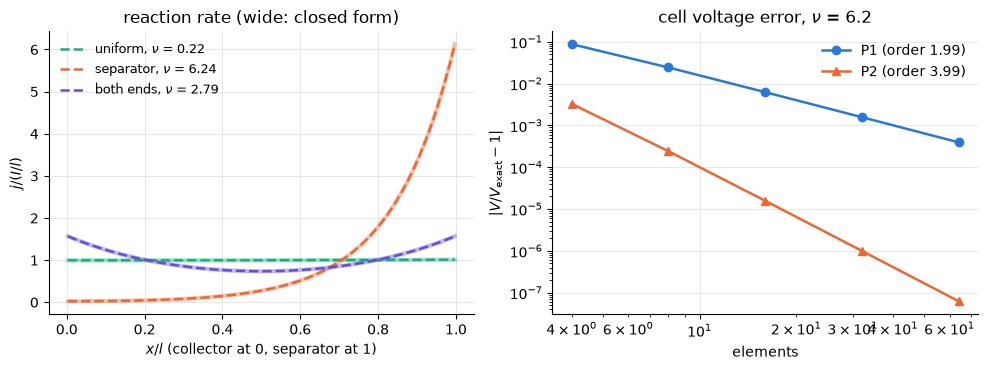

In [14]:
def porous_exact(l, sigma, kappa, a_v, i0, I, x):
    kv = a_v * i0 * f                          # alpha_a + alpha_c = 1
    k = math.sqrt(kv * (1 / sigma + 1 / kappa))
    nu = k * l
    eta = I / (k * math.sinh(nu)) * (np.cosh(k * x) / kappa + np.cosh(k * (l - x)) / sigma)
    R_cell = l / (sigma + kappa) * (1 + (2 + (sigma / kappa + kappa / sigma) * math.cosh(nu)) / (nu * math.sinh(nu)))
    return nu, eta, R_cell


l, a_v, I_cell = 1e-3, 1e5, 10.0        # m, 1/m, A/m^2
cases = {"uniform":   dict(sigma=10.0, kappa=2.5, i0=0.025),
         "separator": dict(sigma=1e4, kappa=2.5, i0=25.0),
         "both ends": dict(sigma=2.5, kappa=2.5, i0=2.5)}

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for (name, c), col in zip(cases.items(), (GREEN, ORANGE, VIOLET)):
    rx = Reaction("linear", i0=c["i0"])
    pe = PorousElectrode(l, 16, order=2)
    pe.setup(c["sigma"], c["kappa"], a_v, rx, I=I_cell)
    rep = pe.solve(temperature=T)
    z = np.asarray(pe.state())
    V_h = z[0] - z[-1]                               # phi1(0) - phi2(l)
    Q = np.asarray(pe.quadrature(8))                 # columns x, w, phi1, phi1', phi2, phi2'
    x, eta_h = Q[:, 0], Q[:, 2] - Q[:, 4]
    nu, eta_x, R_cell = porous_exact(l, c["sigma"], c["kappa"], a_v, c["i0"], I_cell, x)
    print(f"{name:10s} nu = {nu:5.2f}   V = {V_h * 1e3:.8f} mV   closed form {I_cell * R_cell * 1e3:.8f} mV   "
          f"rel. error {V_h / (I_cell * R_cell) - 1:+.1e}   max |eta - eta_exact|/max eta {np.max(np.abs(eta_h - eta_x)) / eta_x.max():.1e}")
    o = np.argsort(x)
    jm = I_cell / l / (a_v * c["i0"] * f)            # eta of a uniform reaction
    ax[0].plot(x[o] / l, eta_x[o] / jm, color=col, lw=3, alpha=0.4)
    ax[0].plot(x[o] / l, eta_h[o] / jm, color=col, ls="--", label=rf"{name}, $\nu$ = {nu:.2f}")
ax[0].set(xlabel="$x/l$ (collector at 0, separator at 1)", ylabel=r"$j/(I/l)$", title="reaction rate (wide: closed form)")
ax[0].legend(fontsize=9)

c = cases["separator"]
for order, col, mk in ((1, BLUE, "o"), (2, ORANGE, "^")):
    Ns, err = [4, 8, 16, 32, 64], []
    for N in Ns:
        pe = PorousElectrode(l, N, order=order)
        pe.setup(c["sigma"], c["kappa"], a_v, Reaction("linear", i0=c["i0"]), I=I_cell)
        pe.solve(temperature=T)
        z = np.asarray(pe.state())
        err.append(abs((z[0] - z[-1]) / (I_cell * porous_exact(l, c["sigma"], c["kappa"], a_v, c["i0"], 1, 0.0)[2]) - 1))
    p = np.polyfit(np.log(1 / np.array(Ns[-3:])), np.log(err[-3:]), 1)[0]
    ax[1].loglog(Ns, err, marker=mk, color=col, label=f"P{order} (order {p:.2f})")
ax[1].set(xlabel="elements", ylabel=r"$|V/V_{\rm exact}-1|$", title=r"cell voltage error, $\nu$ = 6.2")
ax[1].legend()
plt.tight_layout()
plt.show()

The cell voltage converges at second order with P1 and fourth order with P2.

`PorousElectrode` accepts only linearized Butler–Volmer exchange; Butler–Volmer and Tafel exchange are refused
(the last section lists what the test cases cover). The model has no concentration dependence.

In [15]:
pe = PorousElectrode(l, 16, order=1)
try:
    pe.setup(10.0, 2.5, a_v, Reaction("bv", i0=2.5), I=I_cell)
except RuntimeError as e:
    print(textwrap.fill(str(e), 110))

axf::chem::PorousElectrode1D: exchange kinetics 'bv' is not available: the porous electrode supports
linearized Butler-Volmer exchange only; use kind 'linear' (i = i0 (alpha_a + alpha_c) F/(R T) eta). Nonlinear
porous exchange is not implemented


## 5. Tests and validation

The planar and axisymmetric current distribution (sections 1 and 2) is covered by `tests/test_chem_current_distribution.py`, and the 3D and porous-electrode solvers (sections 3 and 4) by `tests/test_chem_current_distribution_3d.py`. The case definitions, with acceptance criteria and reference numbers, are in `benchmarks/chem/` (see its README); `python benchmarks/chem/run.py list` lists them, and `python benchmarks/chem/run.py run --all --cost short` runs the short ones and checks their criteria. A case reports up to four kinds of agreement:

* *self-consistency*: manufactured-solution convergence orders and conservation identities (current balance, electrode areas). These test the discretization, not the physics;
* *exact solution*: closed forms of the same equations (Newman's disk, the concentric cells, the porous electrode), including the convergence orders measured against them;
* *cross-code*: another code's output: DOLFINx at every mesh level, the Legendre series for the secondary disk, and axionFEM's electrostatics solver `ElectroProblem` on primary cases;
* *literature*: values printed in a primary source. No current case makes a claim of that kind.

The current-distribution cases carry no separate comparison with published numbers. Newman's primary disk formulas are the analytic reference of the disk case, so extracting values from the paper would repeat the same test; the secondary disk is compared with an independent series solution and with DOLFINx; the porous closed form is re-derived from Newman and Tobias's equations; the 3D cases are designed geometries without published values. This is not a claim of agreement with the literature beyond those closed forms.

Scope of the solvers: Laplace's equation for $\phi_l$ with piecewise-constant or smoothly varying $\kappa$; primary, Butler-Volmer, linearized and Tafel electrodes, several reactions per surface; potentiostatic and grounded galvanostatic control; the half-space exterior; 3D on one node; and the 1D porous electrode with linearized kinetics. Concentration-dependent transport, the double layer and nonlinear porous exchange are not implemented. The [chemistry guide](../docs/guides/chemistry.md) describes the formulations, and the case files in `benchmarks/chem/registry/cases/` list the reference values.